In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    roc_curve
)

In [2]:
df = pd.read_csv("spam.csv", encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
print("Shape of dataset:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Shape of dataset: (5572, 5)

Column names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

Data types:
v1            object
v2            object
Unnamed: 2    object
Unnamed: 3    object
Unnamed: 4    object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Duplicate rows:
403


In [5]:
df = df[['v1', 'v2']]

df = df.rename(columns={
    'v1': 'label',
    'v2': 'message'
})

df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)

df.head()

Shape after cleaning: (5169, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label
ham     4516
spam     653
Name: count, dtype: int64

Percentage distribution:
label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


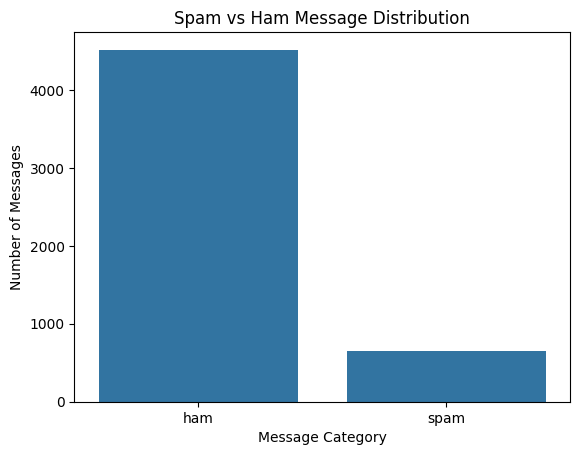

In [6]:
# Count the number of messages in each category
print(df['label'].value_counts())

# Calculate percentage of each category
print("\nPercentage distribution:")
print(df['label'].value_counts(normalize=True) * 100)

# Visualize the class distribution
sns.countplot(x='label', data=df)

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.show()

In [7]:
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

print(df.head())

print("\nTarget variable values:")
print(df['label'].value_counts())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Target variable values:
label
0    4516
1     653
Name: count, dtype: int64


In [8]:
X = df['message']
y = df['label']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 5 messages:")
print(X.head())

print("\nFirst 5 target values:")
print(y.head())

Features shape: (5169,)
Target shape: (5169,)

First 5 messages:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: object

First 5 target values:
0    0
1    0
2    1
3    0
4    0
Name: label, dtype: int64


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (4135,)
Testing data: (1034,)

Training class distribution:
label
0    3613
1     522
Name: count, dtype: int64

Testing class distribution:
label
0    903
1    131
Name: count, dtype: int64


In [10]:
tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

Training feature matrix: (4135, 5000)
Testing feature matrix: (1034, 5000)


In [11]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [12]:
y_pred = model.predict(X_test_tfidf)

y_prob = model.predict_proba(X_test_tfidf)[:, 1]

print("Predicted labels:")
print(y_pred[:10])

print("\nSpam probabilities:")
print(y_prob[:10])

Predicted labels:
[0 0 0 0 0 0 0 0 0 0]

Spam probabilities:
[0.02038272 0.01074807 0.03886234 0.04738615 0.01676035 0.03357379
 0.03728271 0.00637349 0.03924668 0.01623412]


In [13]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9661508704061895
Precision: 0.9897959183673469
Recall: 0.7404580152671756
F1 Score: 0.8471615720524017
ROC-AUC: 0.9893146678163544

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       903
           1       0.99      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



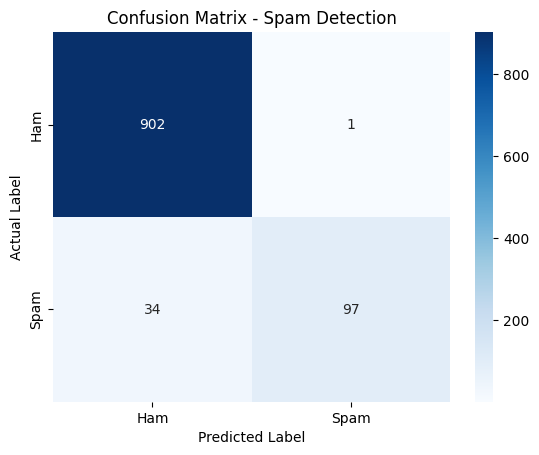

Confusion Matrix:
[[902   1]
 [ 34  97]]


In [14]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Spam Detection")
plt.show()

print("Confusion Matrix:")
print(cm)

In [15]:
thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", accuracy_score(y_test, y_threshold_pred))
    print("Precision:", precision_score(y_test, y_threshold_pred))
    print("Recall:", recall_score(y_test, y_threshold_pred))
    print("F1 Score:", f1_score(y_test, y_threshold_pred))


Threshold: 0.3
Accuracy: 0.9729206963249516
Precision: 0.9401709401709402
Recall: 0.8396946564885496
F1 Score: 0.8870967741935484

Threshold: 0.5
Accuracy: 0.9661508704061895
Precision: 0.9897959183673469
Recall: 0.7404580152671756
F1 Score: 0.8471615720524017

Threshold: 0.7
Accuracy: 0.9381044487427466
Precision: 0.9855072463768116
Recall: 0.5190839694656488
F1 Score: 0.68


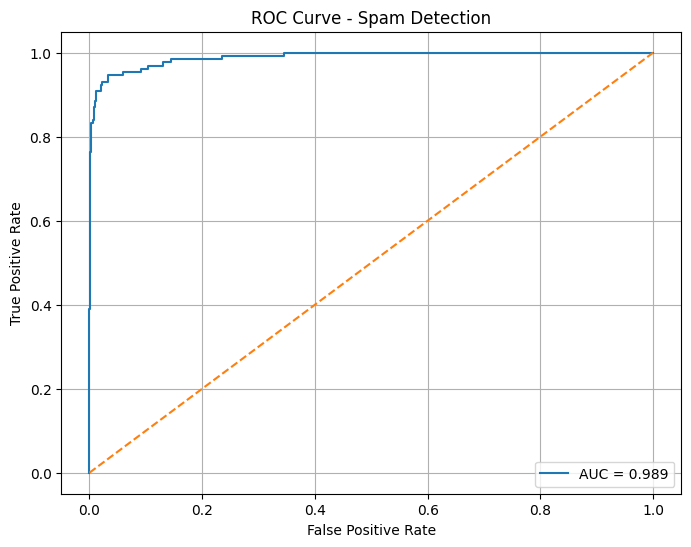

In [16]:
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Spam Detection")
plt.legend()
plt.grid()
plt.show()

In [17]:
majority_class = y_train.mode()[0]

y_baseline = np.full(len(y_test), majority_class)

print("Baseline Accuracy:", accuracy_score(y_test, y_baseline))
print("Baseline Precision:", precision_score(y_test, y_baseline, zero_division=0))
print("Baseline Recall:", recall_score(y_test, y_baseline, zero_division=0))
print("Baseline F1 Score:", f1_score(y_test, y_baseline, zero_division=0))

Baseline Accuracy: 0.8733075435203095
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1 Score: 0.0


In [18]:
new_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting today at 6 pm?"
]

new_messages_tfidf = tfidf.transform(new_messages)

predictions = model.predict(new_messages_tfidf)

probabilities = model.predict_proba(new_messages_tfidf)[:, 1]

for message, prediction, probability in zip(
    new_messages, predictions, probabilities
):
    category = "Spam" if prediction == 1 else "Ham"

    print("Message:", message)
    print("Prediction:", category)
    print("Spam Probability:", round(probability, 4))
    print("-" * 50)

Message: Congratulations! You have won a free prize. Call now!
Prediction: Spam
Spam Probability: 0.8889
--------------------------------------------------
Message: Hey, are we meeting today at 6 pm?
Prediction: Ham
Spam Probability: 0.0263
--------------------------------------------------


## Conclusion

In this activity, SMS Spam Detection was implemented using Logistic Regression. The dataset was cleaned by removing duplicate records and unnecessary columns. The labels were encoded as Ham (0) and Spam (1). TF-IDF was used to convert text messages into numerical features, and the data was divided into training and testing sets using stratified sampling.

The Logistic Regression model was trained and evaluated using Accuracy, Precision, Recall, F1 Score, ROC-AUC, and a Confusion Matrix. Threshold analysis was also performed to study its effect on classification performance. The model successfully classified new SMS messages as Spam or Ham.

The activity demonstrated the application of Logistic Regression to binary text classification and the importance of evaluating a classification model using multiple performance metrics.
